In [13]:
import cv2
import os
import matplotlib.pyplot as plt
import shutil
import random
import yaml
import pandas as pd
from collections import Counter
from ultralytics import YOLO
from IPython.display import Image, display


In [14]:
DATASET_ROOT = './dataset'
TRAIN_PATH = os.path.join(DATASET_ROOT, 'train')
TEST_PATH = os.path.join(DATASET_ROOT, 'test')
SAMPLE15_PATH = os.path.join(DATASET_ROOT, 'sample15')

TRAIN_IMAGES = os.path.join(TRAIN_PATH, 'images')
TRAIN_LABELS = os.path.join(TRAIN_PATH, 'labels')
TEST_IMAGES = os.path.join(TEST_PATH, 'images')
TEST_LABELS = os.path.join(TEST_PATH, 'labels')

DATA_YAML_PATH = os.path.join(DATASET_ROOT, 'data.yaml')


In [15]:
with open(DATA_YAML_PATH, 'r') as f:
    data_yaml = yaml.safe_load(f)
    class_names = data_yaml['names']

print("Classes:", class_names)
print(f"Number of classes: {len(class_names)}")


Classes: ['Ambulance', 'Bus', 'Car', 'Motorcycle', 'Truck']
Number of classes: 5


In [16]:
def get_image_files(directory, limit=None):
    """Get image files from directory with optional limit."""
    files = [f for f in os.listdir(directory) if f.endswith(('.jpg', '.png'))]
    return files[:limit] if limit else files


In [17]:
def yolo_to_coords(yolo_box, img_w, img_h):
    """Convert YOLO format to pixel coordinates."""
    cls, x_c, y_c, w_n, h_n = yolo_box
    x1 = int((x_c - w_n / 2) * img_w)
    y1 = int((y_c - h_n / 2) * img_h)
    x2 = int((x_c + w_n / 2) * img_w)
    y2 = int((y_c + h_n / 2) * img_h)
    return x1, y1, x2, y2

In [18]:
def calculate_iou(box1, box2):
    """Calculate Intersection over Union (IoU) between two boxes."""
    x1_inter = max(box1[0], box2[0])
    y1_inter = max(box1[1], box2[1])
    x2_inter = min(box1[2], box2[2])
    y2_inter = min(box1[3], box2[3])

    inter_width = max(0, x2_inter - x1_inter)
    inter_height = max(0, y2_inter - y1_inter)
    intersection_area = inter_width * inter_height

    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union_area = box1_area + box2_area - intersection_area
    
    return intersection_area / union_area if union_area > 0 else 0



In [19]:
def draw_yolo_labels(img, label_file_path, class_names, color=(0, 255, 0)):
    """Draw YOLO bounding boxes on image."""
    if not os.path.exists(label_file_path):
        return img
        
    h, w = img.shape[:2]
    with open(label_file_path, 'r') as f:
        for line in f.readlines():
            parts = line.strip().split()
            cls, x, y, bw, bh = map(float, parts[:5])
            
            x1, y1, x2, y2 = yolo_to_coords((cls, x, y, bw, bh), w, h)
            # Draw rectangle and label
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            label_text = class_names[int(cls)] if class_names else f'Class {int(cls)}'
            cv2.putText(img, label_text, (x1, y1 - 5), 
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    return img

In [20]:
def load_boxes_from_file(file_path):
    """Load bounding boxes from YOLO format file."""
    if not os.path.exists(file_path):
        return []
    with open(file_path, 'r') as f:
        return [list(map(float, line.strip().split())) for line in f.readlines()]


In [21]:
def count_class_instances(label_dir):
    """Count instances of each class in label directory."""
    class_counts = Counter()
    for fname in os.listdir(label_dir):
        if not fname.endswith('.txt'):
            continue
        with open(os.path.join(label_dir, fname), 'r') as f:
            for line in f:
                cls_id = int(line.strip().split()[0])
                class_counts[cls_id] += 1
    return class_counts

In [22]:
def get_class_ratios(label_dir, class_names):
    """Calculate class distribution ratios."""
    total_count = 0
    class_counts = Counter()

    for fname in os.listdir(label_dir):
        if not fname.endswith('.txt'):
            continue
        with open(os.path.join(label_dir, fname), 'r') as f:
            for line in f:
                cls_id = int(line.strip().split()[0])
                class_counts[cls_id] += 1
                total_count += 1

    class_ratios = {class_names[cls_id]: count / total_count for cls_id, count in class_counts.items()}
    
    # Ensure all classes appear (even if 0%)
    for cls_id, name in enumerate(class_names):
        class_ratios.setdefault(name, 0.0)
    
    return class_ratios



In [23]:
def compute_overall_iou(img_dir, gt_dir, pred_dir):
    """Compute overall IoU across all images."""
    image_files = get_image_files(img_dir)
    total_ious = []

    for img_name in image_files:
        base = os.path.splitext(img_name)[0]
        gt_label_path = os.path.join(gt_dir, base + '.txt')
        pred_label_path = os.path.join(pred_dir, base + '.txt')
        img_path = os.path.join(img_dir, img_name)

        if not os.path.exists(gt_label_path):
            continue

        img = cv2.imread(img_path)
        h, w = img.shape[:2]

        gt_boxes = load_boxes_from_file(gt_label_path)
        pred_boxes = load_boxes_from_file(pred_label_path)

        for gt_box in gt_boxes:
            best_iou = 0
            for pred_box in pred_boxes:
                if int(gt_box[0]) == int(pred_box[0]):  # Class match
                    iou = calculate_iou(
                        yolo_to_coords(gt_box, w, h),
                        yolo_to_coords(pred_box[:5], w, h)
                    )
                    best_iou = max(best_iou, iou)
            
            if best_iou > 0:
                total_ious.append(best_iou)

    return sum(total_ious) / len(total_ious) if total_ious else 0.0

In [25]:
print("\nClass distribution in training set:")
for cls_id, count in train_class_counts.items():
    class_name = class_names[cls_id]
    percentage = train_class_ratios[class_name] * 100
    print(f"  {class_name}: {count} instances ({percentage:.1f}%)")


Class distribution in training set:


NameError: name 'train_class_counts' is not defined

In [24]:
def create_sample15_dataset():
    """Create sample dataset with 15 random test images."""
    # Get random sample of 15 images
    all_images = get_image_files(TEST_IMAGES)
    sample_images = random.sample(all_images, 15)
    print("Selected images:", sample_images)
    
    # Create directories
    os.makedirs(os.path.join(SAMPLE15_PATH, 'images'), exist_ok=True)
    os.makedirs(os.path.join(SAMPLE15_PATH, 'labels'), exist_ok=True)
    
    # Copy images
    print(f"Copying {len(sample_images)} images...")
    for img in sample_images:
        src_img = os.path.join(TEST_IMAGES, img)
        dst_img = os.path.join(SAMPLE15_PATH, 'images', img)
        shutil.copy(src_img, dst_img)
    
    # Copy labels
    print("Copying corresponding labels...")
    for img in sample_images:
        label_file = img.rsplit('.', 1)[0] + '.txt'
        src_label = os.path.join(TEST_LABELS, label_file)
        dst_label = os.path.join(SAMPLE15_PATH, 'labels', label_file)
        if os.path.exists(src_label):
            shutil.copy(src_label, dst_label)
        else:
            print(f"Warning: No label file found for {img}")
    
    print(f"Random sample15 dataset created successfully!")
    return sample_images


sample_images = create_sample15_dataset()

Selected images: ['cf165ec304d2b2dc_jpg.rf.EBBLjKokT5TYAEPvd35E.jpg', '9ca8e20e0869f289_jpg.rf.ScBMQ9VslO942N7rh8rz.jpg', 'd66aabbb1f7299cc_jpg.rf.BmdIwlEED5bAslMh9Qib.jpg', '4ecafc9a0bae8003_jpg.rf.2UbsFgyK4QxCrSNix6wM.jpg', '259ff749ac781352_jpg.rf.8acc4aba3916d2dd58c3acca8890194b.jpg', 'e36e433eed49a09d_jpg.rf.8826d7fb567c1288c0188105137f280a.jpg', '778f80f86cd35fca_jpg.rf.74dd531b37bb62f4d40e624dcd9d44d3.jpg', '1ef77c61856d3b4b_jpg.rf.a528f50763101224fad39907062c5026.jpg', '861be2a154763b07_jpg.rf.nvXuwhf3jtMFPo9ZSdaA.jpg', '64918de984156adf_jpg.rf.b1255cf890c76ce326916ffcc9e2ca2d.jpg', '259ff749ac781352_jpg.rf.CZyKDHyPjIcTpIwNJ2rd.jpg', '3281f85bb3265523_jpg.rf.3d2bbcf2b4bd95523d7be04566ae2565.jpg', '58163cb625c30451_jpg.rf.f224c9704e2d5d99e2da9e3815ce4374.jpg', '95bf6406c152cf40_jpg.rf.2KlhzCSeifqpfUPfwyW9.jpg', '47b09b34e24b4039_jpg.rf.SXhYsnLDkwnvDNU811ds.jpg']
Copying 15 images...
Copying corresponding labels...
Random sample15 dataset created successfully!


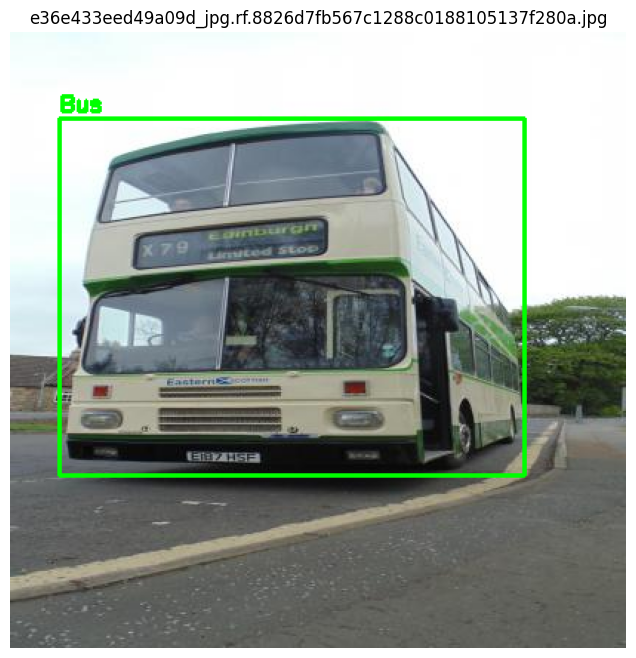

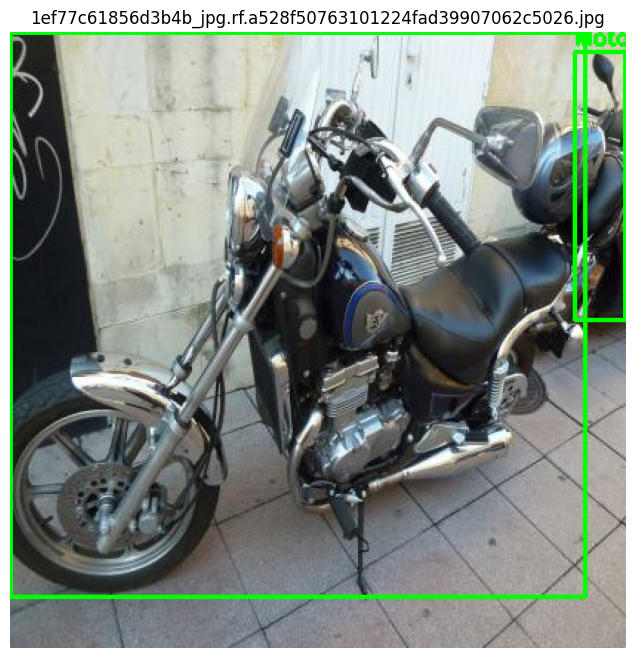

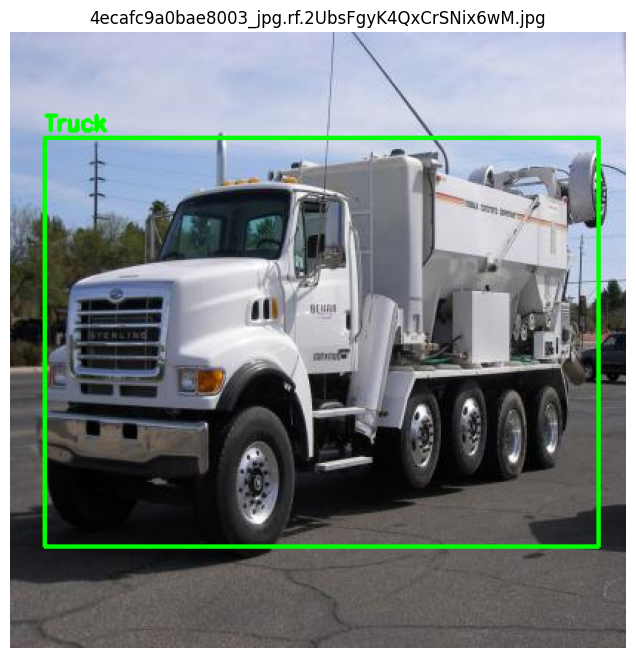

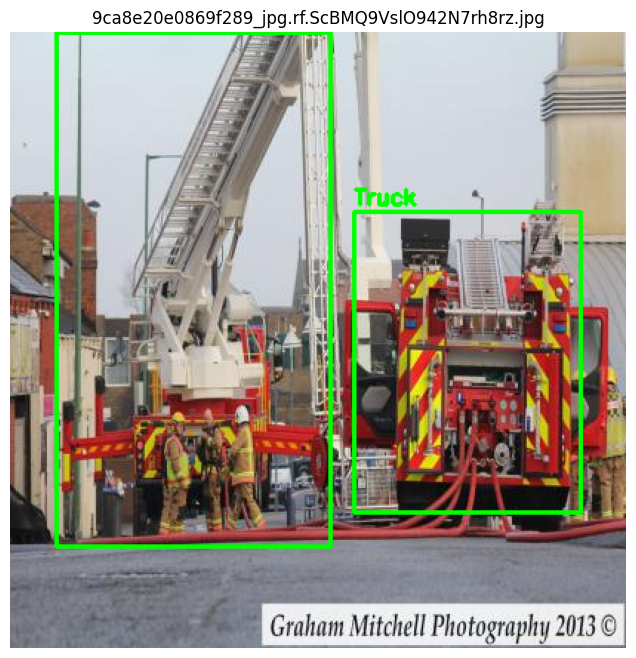

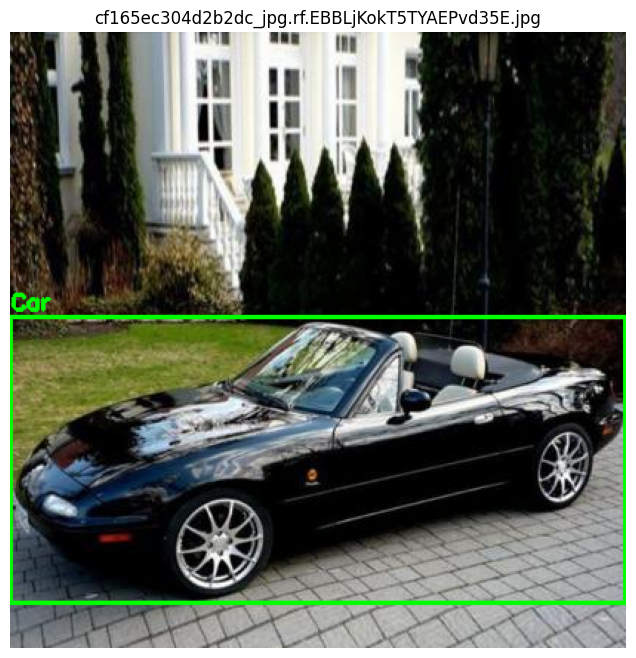

...

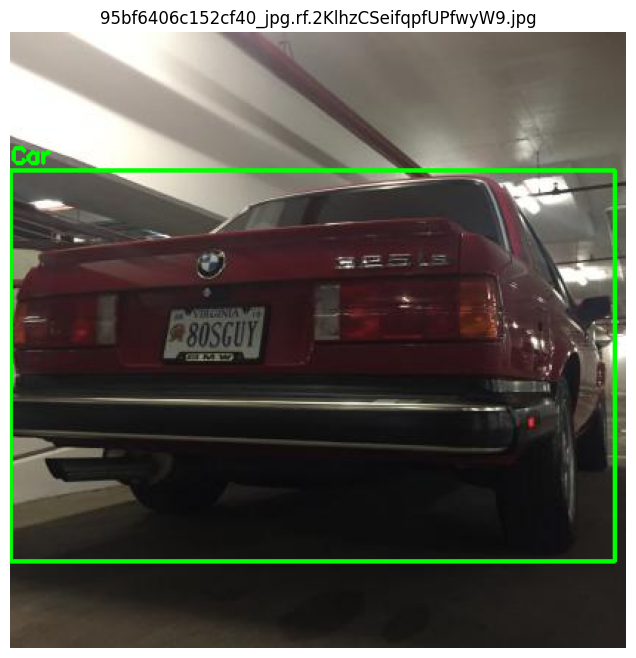

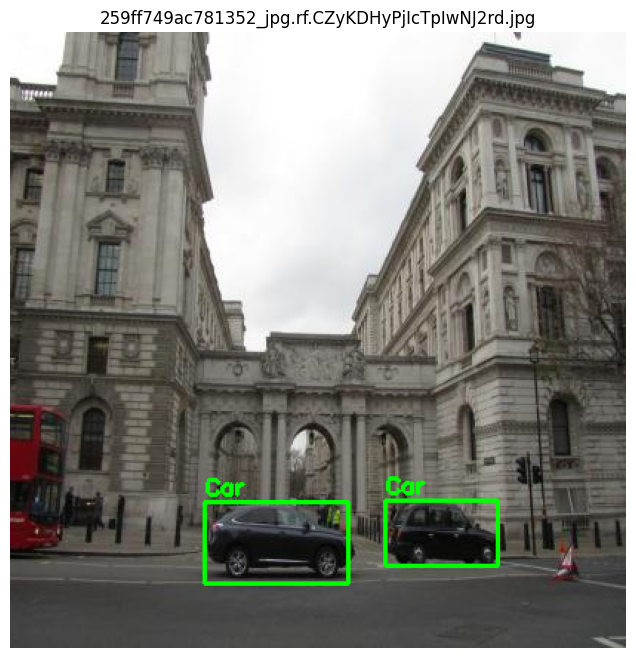

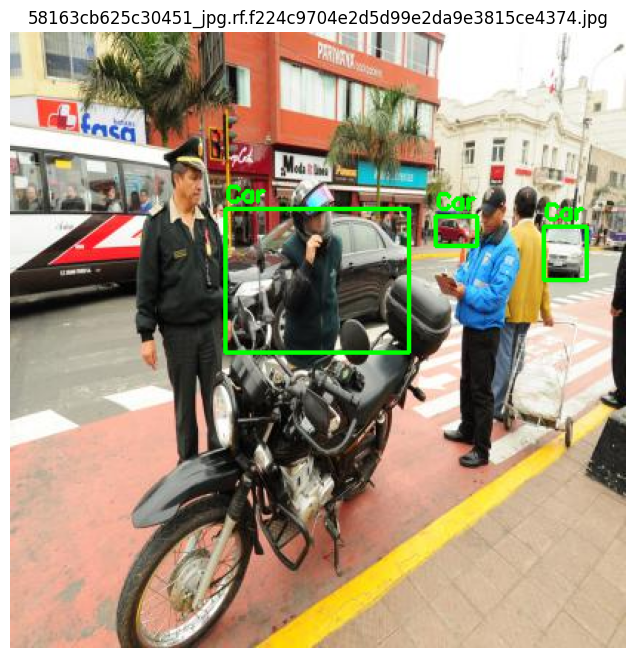

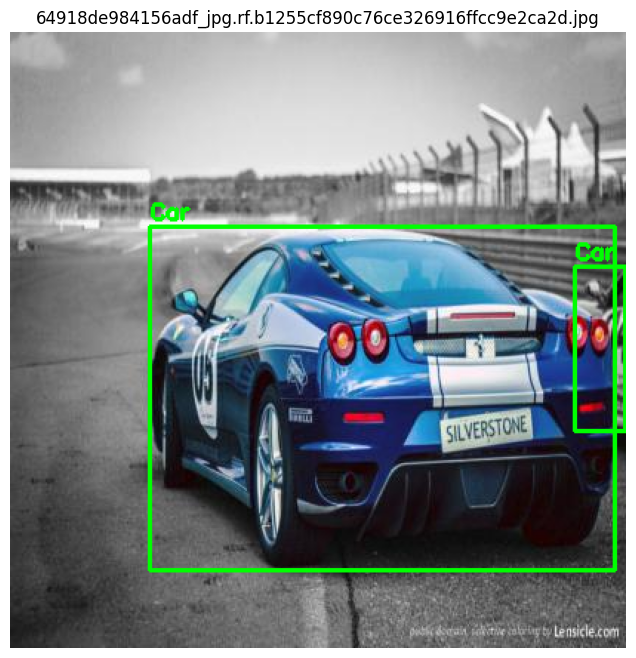

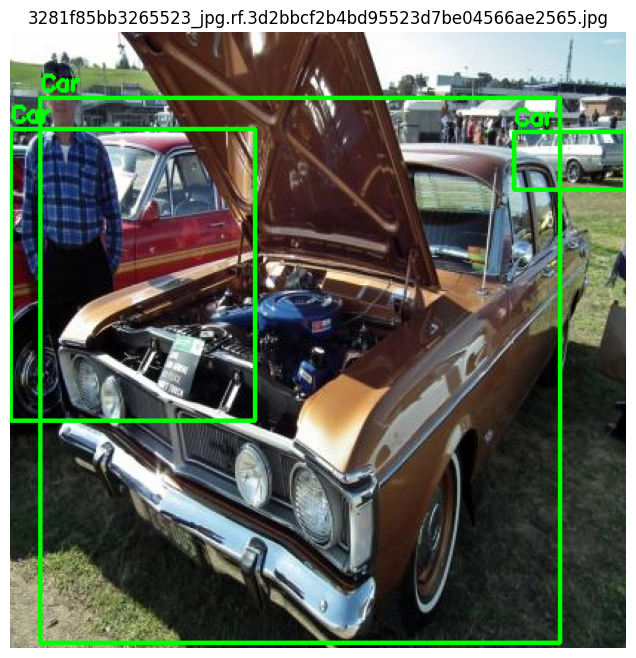

In [26]:
SAMPLE_IMAGES = './dataset/sample15/images'
SAMPLE_LABELS = './dataset/sample15/labels'

def get_image_files(folder, limit=None):
    valid_exts = ['.jpg', '.png']
    files = [f for f in os.listdir(folder) if os.path.splitext(f)[1].lower() in valid_exts]
    return files[:limit] if limit else files

# Get up to 15 sample images
image_files = get_image_files(SAMPLE_IMAGES, limit=15)

for fname in image_files:
    img_path = os.path.join(SAMPLE_IMAGES, fname)
    label_path = os.path.join(SAMPLE_LABELS, 
                              fname.replace('.jpg', '.txt').replace('.png', '.txt'))

    img = cv2.imread(img_path)
    if img is None:
        print(f"Failed to read image {img_path}")
        continue

    img_with_labels = draw_yolo_labels(img.copy(), label_path, class_names)
    
    img_rgb = cv2.cvtColor(img_with_labels, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8))
    plt.imshow(img_rgb)
    plt.title(fname)
    plt.axis('off')
    plt.show()

In [29]:
model = YOLO('best_car_detector.pt')


In [32]:
sample_results = model.predict(
    source=os.path.join(SAMPLE15_PATH, 'images'),
    save=True,
    save_txt=True,
    project='runs/detect',
    name='predict_sample15'
)



image 1/15 /Users/rokiialaa/Downloads/CarsDetection/dataset/sample15/images/1ef77c61856d3b4b_jpg.rf.a528f50763101224fad39907062c5026.jpg: 640x640 2 Motorcycles, 83.6ms
image 2/15 /Users/rokiialaa/Downloads/CarsDetection/dataset/sample15/images/259ff749ac781352_jpg.rf.8acc4aba3916d2dd58c3acca8890194b.jpg: 640x640 1 Bus, 2 Cars, 63.3ms
image 3/15 /Users/rokiialaa/Downloads/CarsDetection/dataset/sample15/images/259ff749ac781352_jpg.rf.CZyKDHyPjIcTpIwNJ2rd.jpg: 640x640 1 Bus, 2 Cars, 59.2ms
image 4/15 /Users/rokiialaa/Downloads/CarsDetection/dataset/sample15/images/3281f85bb3265523_jpg.rf.3d2bbcf2b4bd95523d7be04566ae2565.jpg: 640x640 2 Cars, 57.2ms
image 5/15 /Users/rokiialaa/Downloads/CarsDetection/dataset/sample15/images/47b09b34e24b4039_jpg.rf.SXhYsnLDkwnvDNU811ds.jpg: 640x640 2 Buss, 61.4ms
image 6/15 /Users/rokiialaa/Downloads/CarsDetection/dataset/sample15/images/4ecafc9a0bae8003_jpg.rf.2UbsFgyK4QxCrSNix6wM.jpg: 640x640 1 Car, 1 Truck, 64.2ms
image 7/15 /Users/rokiialaa/Downloads/Ca

In [33]:
full_results = model.predict(
    source=TEST_IMAGES,
    save=True,
    save_txt=True,
    project='runs/detect',
    name='predict_fulltest'
)


image 1/126 /Users/rokiialaa/Downloads/CarsDetection/dataset/test/images/00dea1edf14f09ab_jpg.rf.3f17c8790a68659d03b1939a59ccda80.jpg: 640x640 1 Ambulance, 125.5ms
image 2/126 /Users/rokiialaa/Downloads/CarsDetection/dataset/test/images/00dea1edf14f09ab_jpg.rf.KJ730oDTFPdXdJxvSLnX.jpg: 640x640 1 Ambulance, 61.1ms
image 3/126 /Users/rokiialaa/Downloads/CarsDetection/dataset/test/images/00e481ea1a520175_jpg.rf.6e6a8b3b45c9a11d106958f88ff714ea.jpg: 640x640 2 Buss, 60.2ms
image 4/126 /Users/rokiialaa/Downloads/CarsDetection/dataset/test/images/00e481ea1a520175_jpg.rf.MV6sZ8QCFwFeMYaI2tHm.jpg: 640x640 2 Buss, 63.8ms
image 5/126 /Users/rokiialaa/Downloads/CarsDetection/dataset/test/images/08c8b73e0c2e296e_jpg.rf.7IkYAamjZhnwsoXSrwKt.jpg: 640x640 1 Bus, 63.6ms
image 6/126 /Users/rokiialaa/Downloads/CarsDetection/dataset/test/images/08c8b73e0c2e296e_jpg.rf.effa65856584463c08848031cab357b9.jpg: 640x640 1 Bus, 60.9ms
image 7/126 /Users/rokiialaa/Downloads/CarsDetection/dataset/test/images/10c26

In [48]:
sample_val = model.val(data="/Users/rokiialaa/Downloads/CarsDetection/dataset/sample15.yaml", split='test')


Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.7.1 CPU (Apple M2)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 149.3±48.0 MB/s, size: 31.5 KB)


val: Scanning /Users/rokiialaa/Downloads/CarsDetection/dataset/sample15/labels... 15 images, 0 backgrounds, 0 corrupt: 100%|██████████| 15/15 [00:00<00:00, 2068.06it/s]

val: New cache created: /Users/rokiialaa/Downloads/CarsDetection/dataset/sample15/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:01<00:00,  1.37s/it]


                   all         15         33      0.809      0.679      0.743      0.617
             Ambulance          1          1       0.72          1      0.995      0.995
                   Bus          2          3          1      0.876      0.995      0.819
                   Car          9         24      0.943      0.684      0.828      0.499
            Motorcycle          1          2      0.597        0.5      0.529      0.463
                 Truck          2          3      0.785      0.333      0.366      0.311
Speed: 1.4ms preprocess, 81.5ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to runs/detect/val8


In [49]:
full_val = model.val(data=DATA_YAML_PATH, split='test')


Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.7.1 CPU (Apple M2)
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 124.3±23.5 MB/s, size: 30.4 KB)


val: Scanning /Users/rokiialaa/Downloads/CarsDetection/dataset/test/labels.cache... 126 images, 0 backgrounds, 0 corrupt: 100%|██████████| 126/126 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 8/8 [00:18<00:00,  2.32s/it]


                   all        126        258      0.798      0.671      0.713      0.536
             Ambulance         18         18      0.951          1      0.995      0.927
                   Bus         22         38      0.782      0.754      0.776      0.582
                   Car         60        150      0.736       0.64      0.686      0.448
            Motorcycle         12         32      0.561      0.562      0.544      0.275
                 Truck         14         20      0.959        0.4      0.566       0.45
Speed: 1.4ms preprocess, 141.5ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to runs/detect/val9


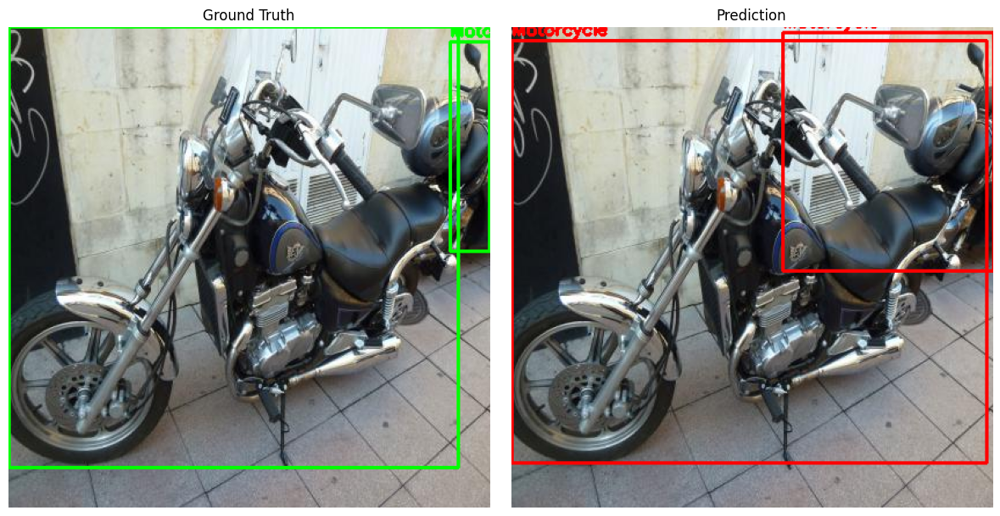

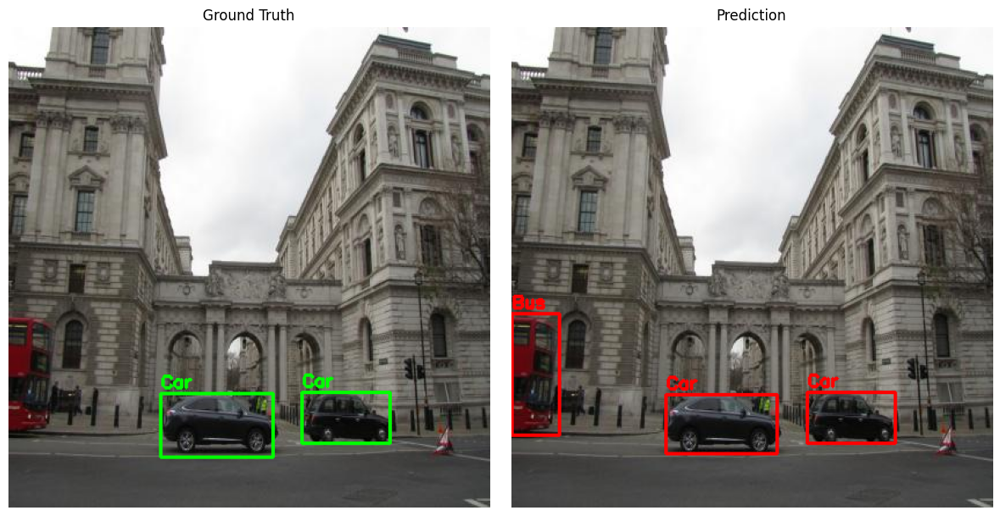

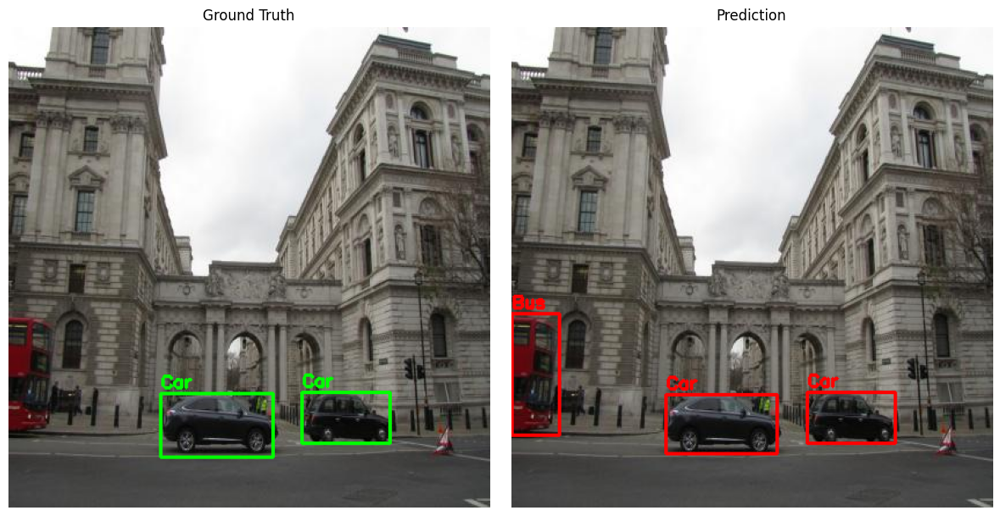

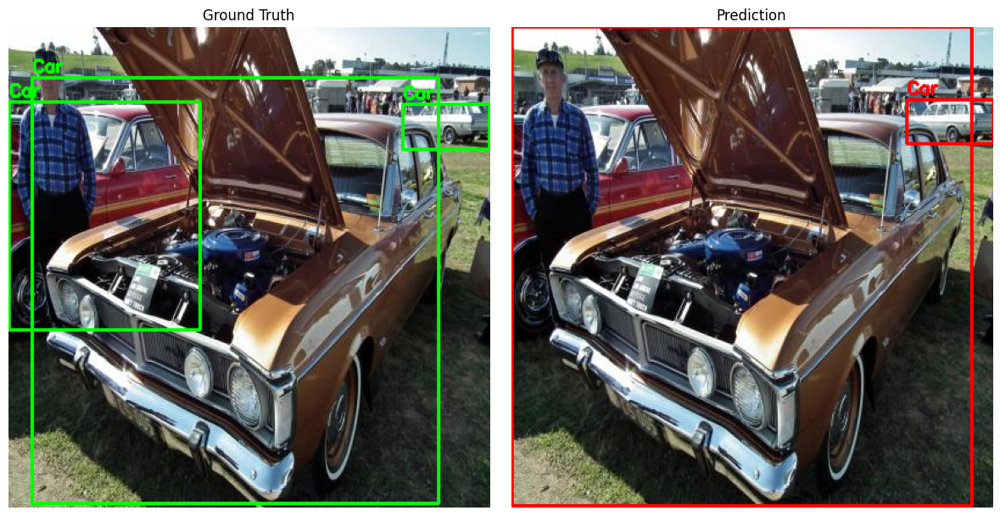

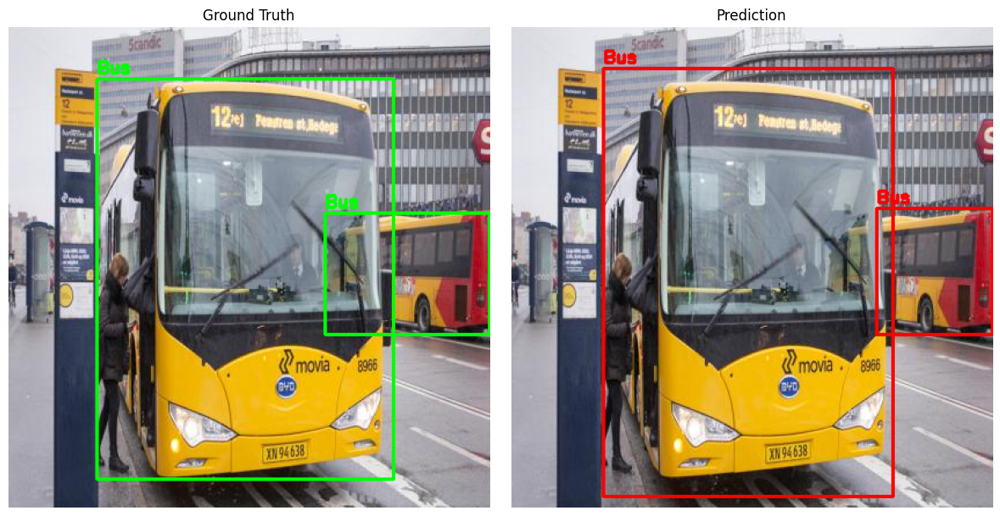

...

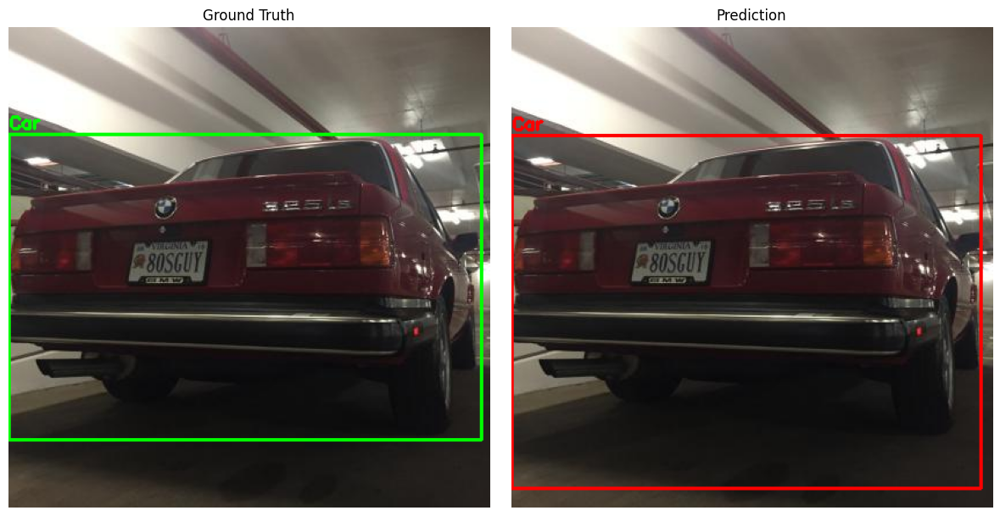

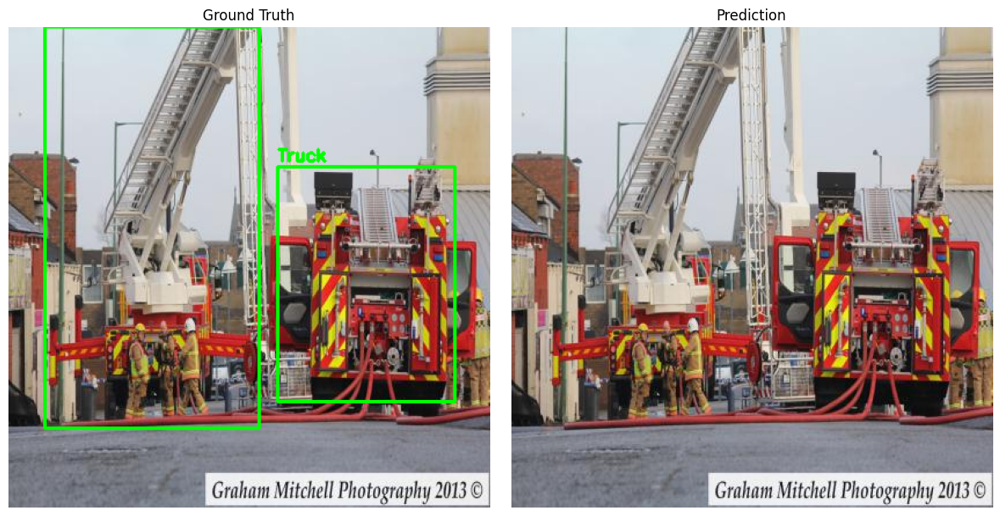

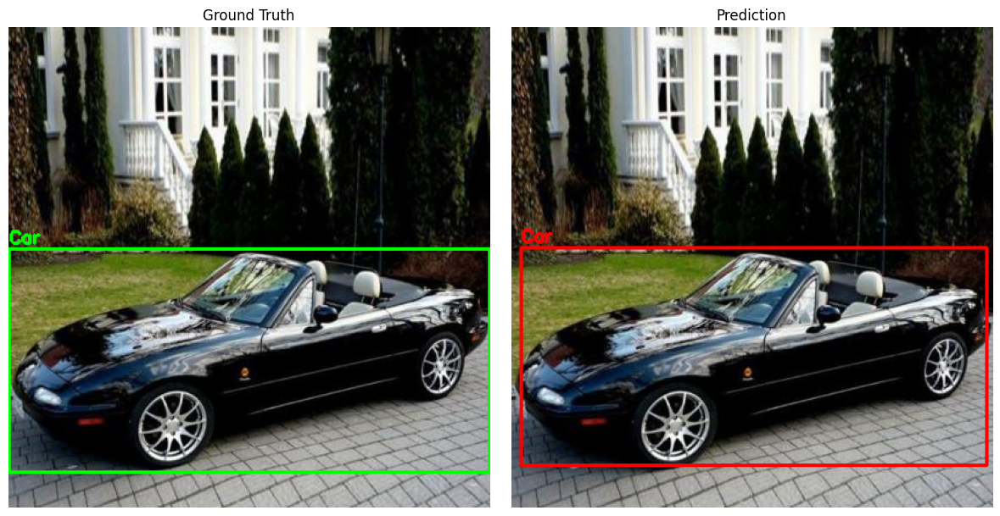

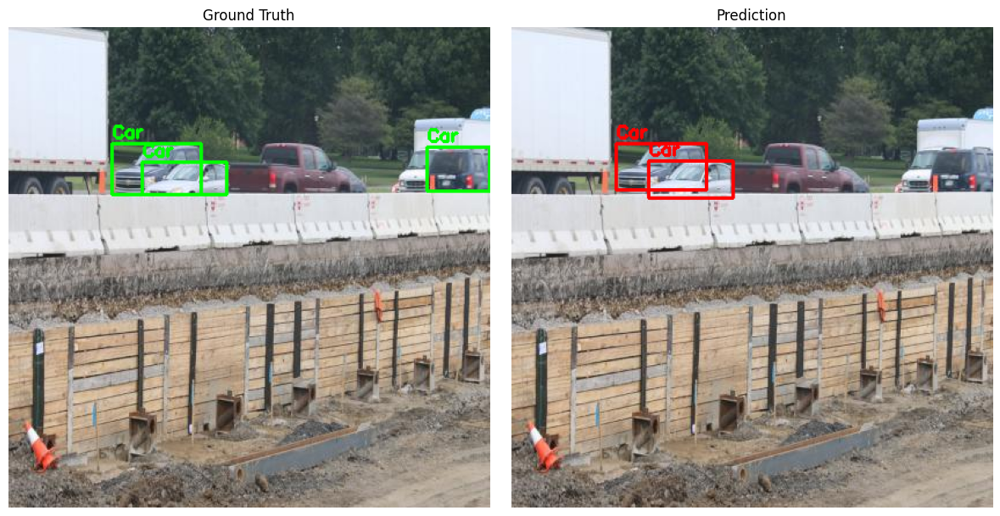

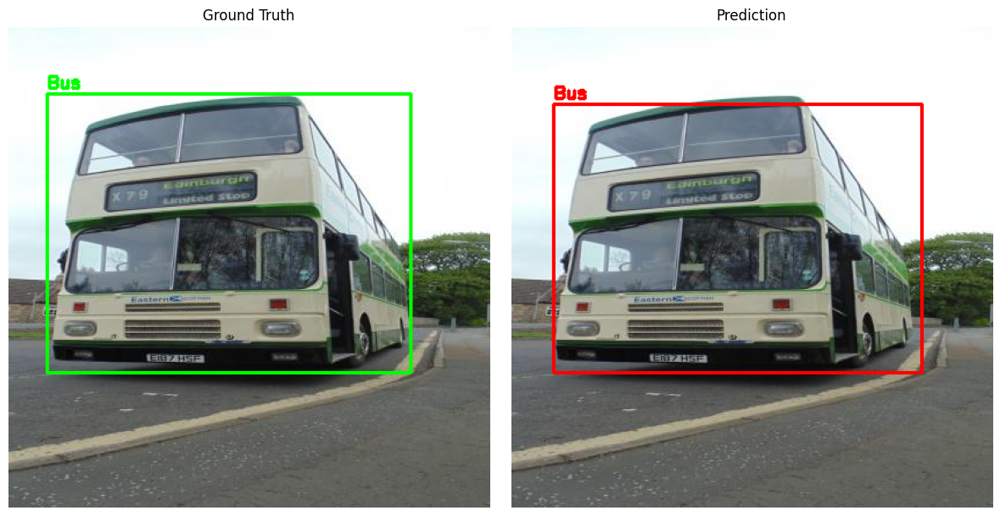

In [27]:
def compare_gt_vs_predictions(img_dir, gt_dir, pred_dir, limit=15):
    """Compare ground truth vs predictions side by side."""
    image_files = sorted(os.listdir(img_dir))[:limit]

    for img_name in image_files:
        img_path = os.path.join(img_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        base_name = os.path.splitext(img_name)[0] + '.txt'
        gt_label = os.path.join(gt_dir, base_name)
        pred_label = os.path.join(pred_dir, base_name)

        gt_img = draw_yolo_labels(img.copy(), gt_label, class_names, color=(0,255,0))
        pred_img = draw_yolo_labels(img.copy(), pred_label, class_names, color=(255,0,0))

        # Side by side comparison
        fig, axs = plt.subplots(1, 2, figsize=(12,6))
        axs[0].imshow(gt_img)
        axs[0].set_title('Ground Truth')
        axs[0].axis('off')
        axs[1].imshow(pred_img)
        axs[1].set_title('Prediction')
        axs[1].axis('off')
        plt.tight_layout()
        plt.show()

# %%
# Compare GT vs Predictions for sample15
compare_gt_vs_predictions(
    os.path.join(SAMPLE15_PATH, 'images'),
    TEST_LABELS,
    './runs/detect/predict_sample15/labels'
)


In [28]:
sample_class_counts = count_class_instances(SAMPLE_LABELS)
print("class counts in sample15 dataset:")
for cls_id, count in sample_class_counts.items():
    print(f"  {class_names[cls_id]}: {count} instances")

class counts in sample15 dataset:
  Car: 24 instances
  Ambulance: 1 instances
  Truck: 3 instances
  Motorcycle: 2 instances
  Bus: 3 instances


In [29]:
PRED_LABELS_SAMPLE15 = './runs/detect/predict_sample15/labels'

gt_counts = count_class_instances(SAMPLE_LABELS)
pred_counts = count_class_instances(PRED_LABELS_SAMPLE15)

print("\nGT vs Predicted Instances in Sample15:")
print(f"{'Class':<12} | {'GT Count':<9} | {'Pred Count':<11}")
print("-" * 40)
for i, name in enumerate(class_names):
    gt = gt_counts.get(i, 0)
    pred = pred_counts.get(i, 0)
    print(f"{name:<12} | {gt:<9} | {pred:<11}")



GT vs Predicted Instances in Sample15:
Class        | GT Count  | Pred Count 
----------------------------------------
Ambulance    | 1         | 1          
Bus          | 3         | 5          
Car          | 24        | 23         
Motorcycle   | 2         | 3          
Truck        | 3         | 1          


In [30]:
def compute_iou_per_box(img_dir, gt_dir, pred_dir):
    """Compute IoU for each GT-pred pair in all images (class matched)."""
    image_files = get_image_files(img_dir)
    per_box_ious = []

    for img_name in image_files:
        base = os.path.splitext(img_name)[0]
        gt_label_path = os.path.join(gt_dir, base + '.txt')
        pred_label_path = os.path.join(pred_dir, base + '.txt')
        img_path = os.path.join(img_dir, img_name)

        if not os.path.exists(gt_label_path) or not os.path.exists(pred_label_path):
            continue

        img = cv2.imread(img_path)
        h, w = img.shape[:2]

        gt_boxes = load_boxes_from_file(gt_label_path)
        pred_boxes = load_boxes_from_file(pred_label_path)

        for gt_box in gt_boxes:
            best_iou = 0
            matched_pred = None

            for pred_box in pred_boxes:
                if int(gt_box[0]) == int(pred_box[0]):  # Class match
                    iou = calculate_iou(
                        yolo_to_coords(gt_box, w, h),
                        yolo_to_coords(pred_box[:5], w, h)
                    )
                    if iou > best_iou:
                        best_iou = iou
                        matched_pred = pred_box

            if matched_pred:
                per_box_ious.append((class_names[int(gt_box[0])], best_iou))

    return per_box_ious


In [32]:
per_box_ious = compute_iou_per_box(
    SAMPLE_IMAGES,
    SAMPLE_LABELS,
    PRED_LABELS_SAMPLE15
)

from collections import defaultdict

ious_per_class = defaultdict(list)
for cls_name, iou in per_box_ious:
    ious_per_class[cls_name].append(iou)

print("\nAverage IoU per Class (Sample15):")
for cls in class_names:
    ious = ious_per_class.get(cls, [])
    if ious:
        avg_iou = sum(ious) / len(ious)
        print(f"  {cls:<12}: {avg_iou:.3f} over {len(ious)} matched boxes")
    else:
        print(f"  {cls:<12}: No matched predictions")




Average IoU per Class (Sample15):
  Ambulance   : 0.936 over 1 matched boxes
  Bus         : 0.845 over 3 matched boxes
  Car         : 0.716 over 22 matched boxes
  Motorcycle  : 0.536 over 2 matched boxes
  Truck       : 0.888 over 1 matched boxes


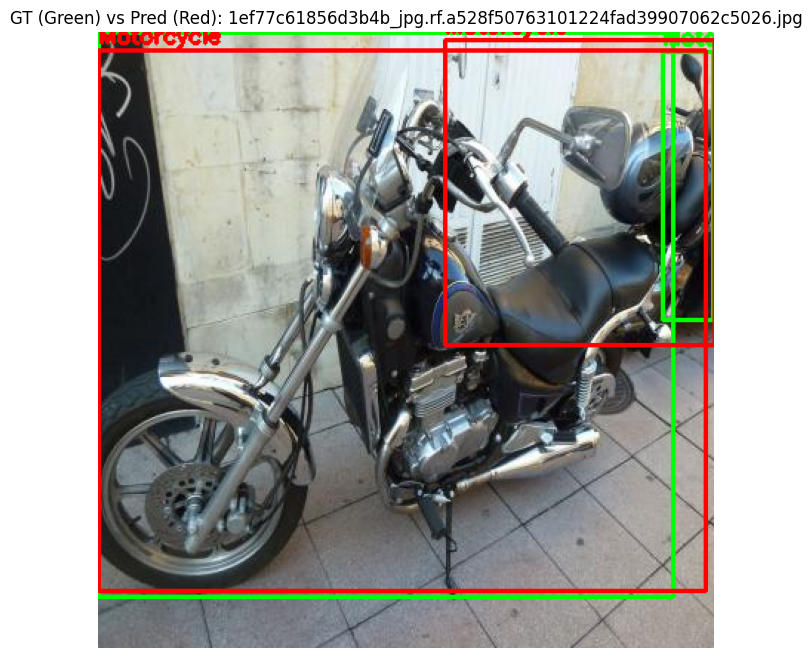

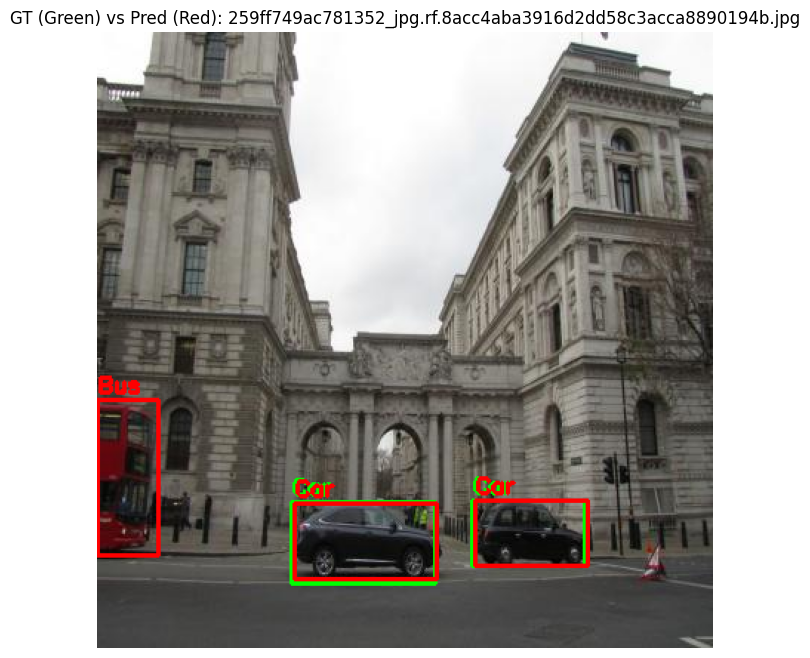

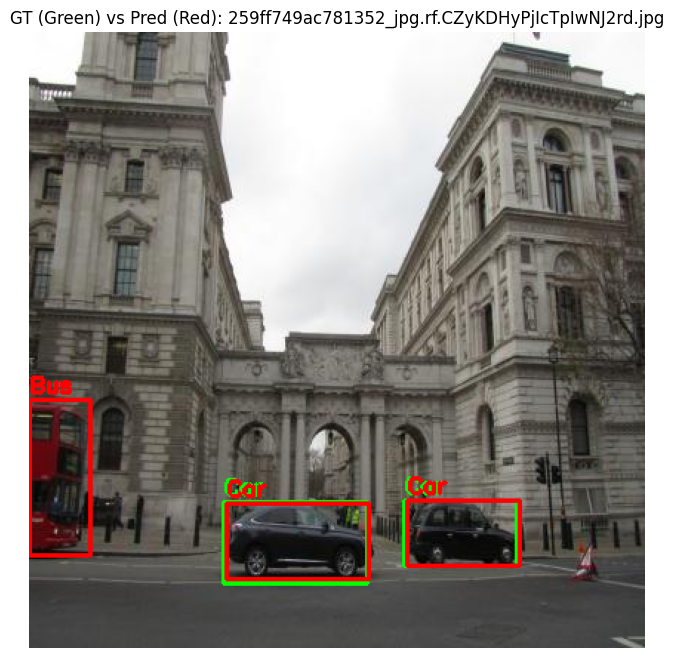

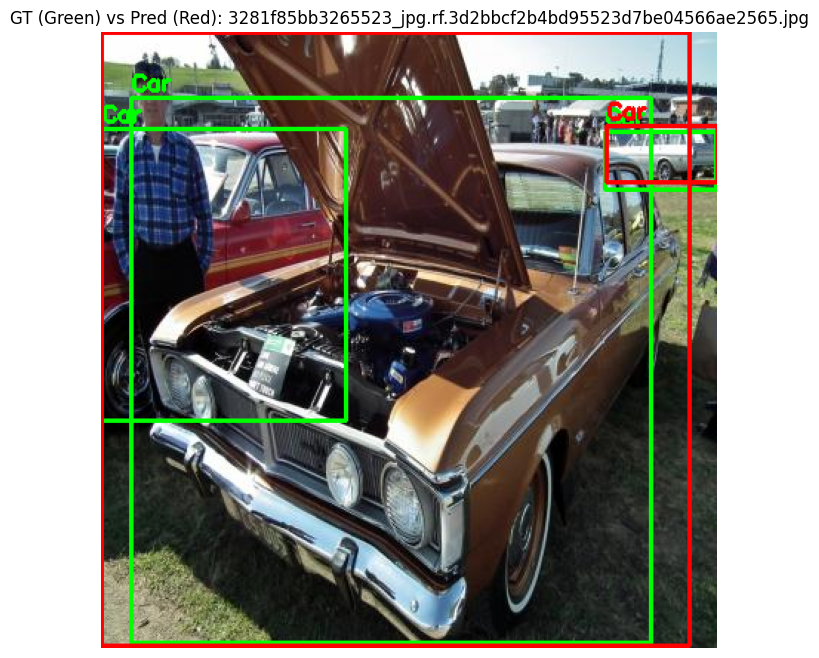

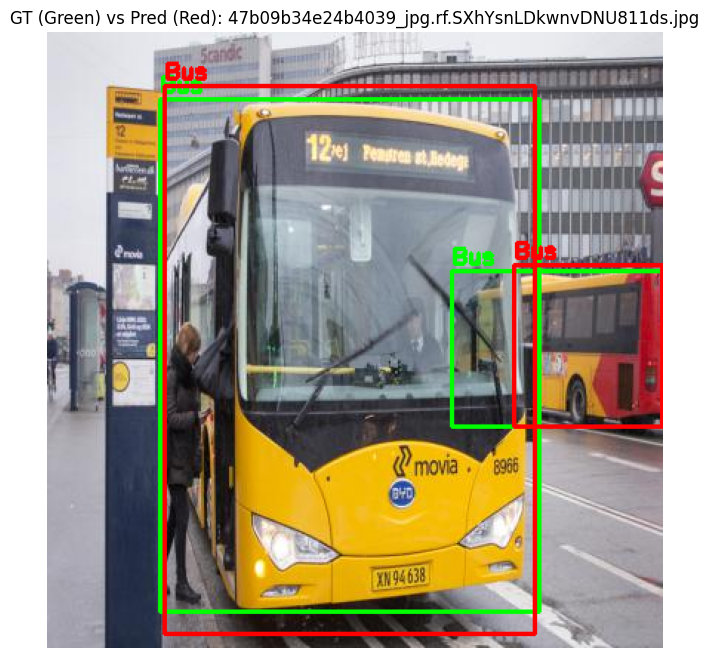

...

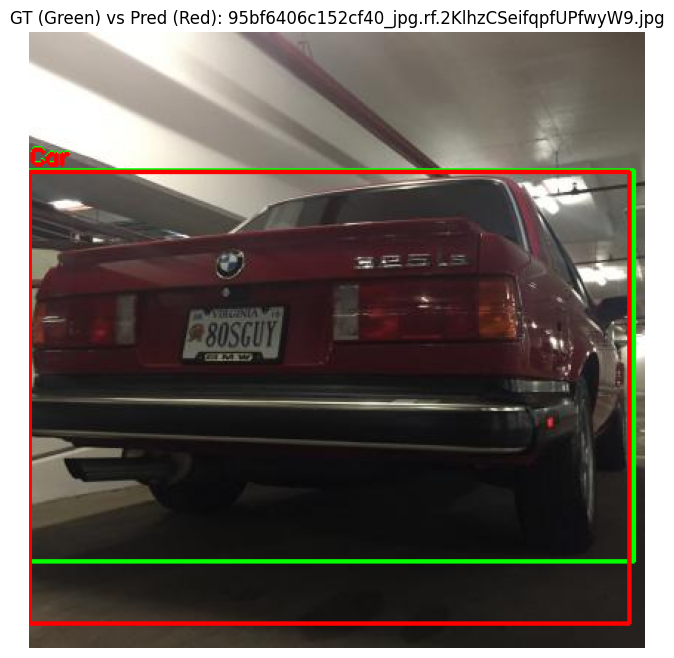

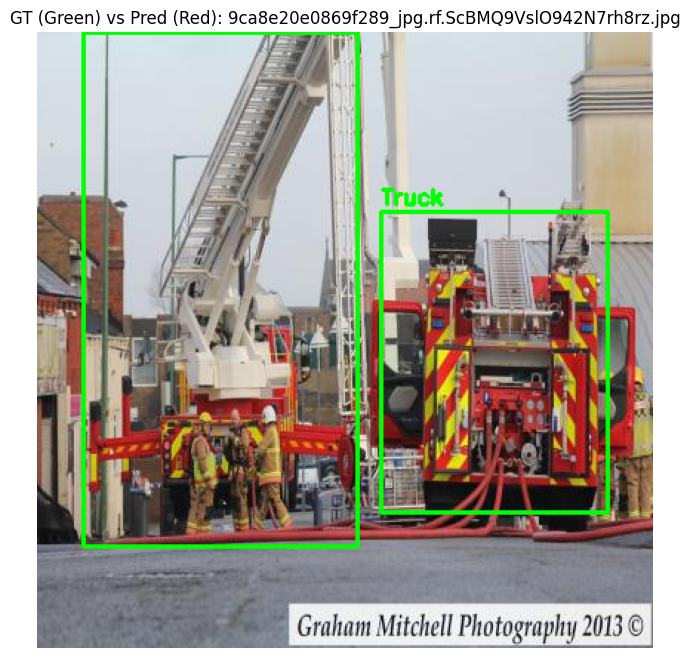

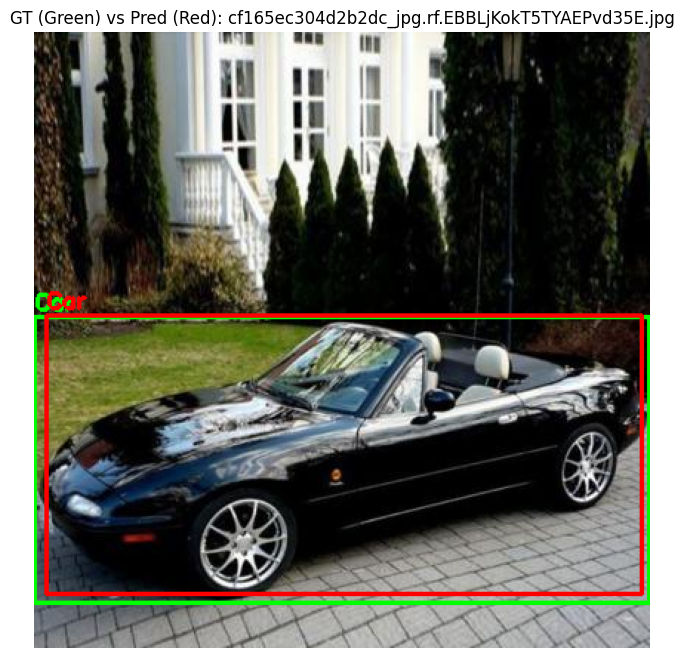

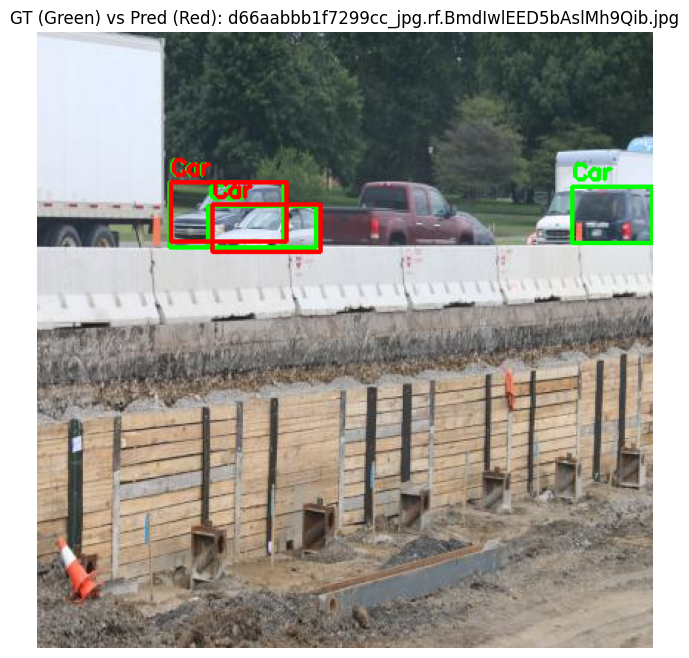

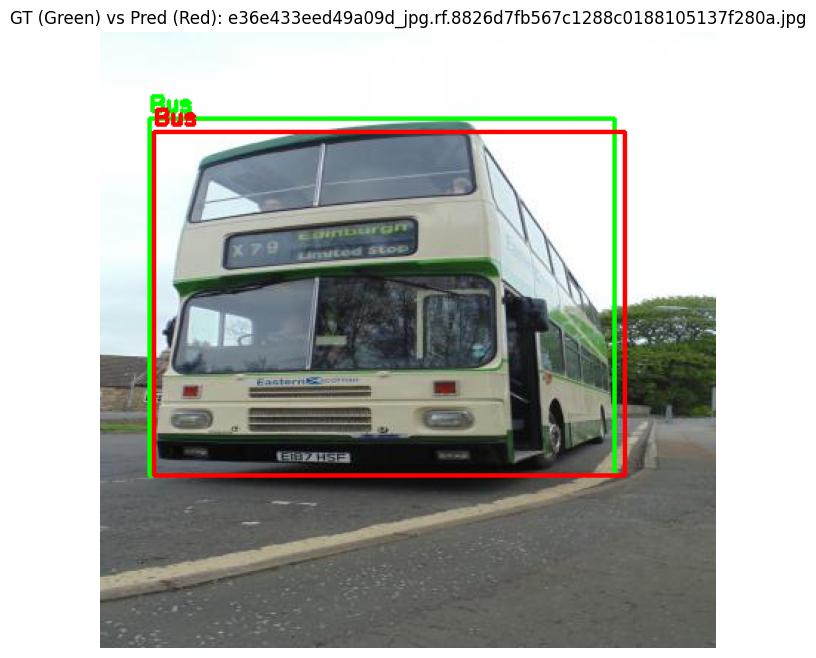

In [67]:
def compare_gt_vs_predictions_overlay(img_dir, gt_dir, pred_dir, limit=15):
    """Compare ground truth vs predictions on same image."""
    image_files = sorted(os.listdir(img_dir))[:limit]
    
    for img_name in image_files:
        img_path = os.path.join(img_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        base = os.path.splitext(img_name)[0] + '.txt'
        gt_label = os.path.join(gt_dir, base)
        pred_label = os.path.join(pred_dir, base)

        combined = img.copy()
        combined = draw_yolo_labels(combined, gt_label, class_names, color=(0, 255, 0))  # Green = GT
        combined = draw_yolo_labels(combined, pred_label, class_names, color=(255, 0, 0))  # Red = Pred

        plt.figure(figsize=(10, 8))
        plt.imshow(combined)
        plt.title(f"GT (Green) vs Pred (Red): {img_name}")
        plt.axis('off')
        plt.show()

# %%
# Overlay comparison for sample15
compare_gt_vs_predictions_overlay(
    os.path.join(SAMPLE15_PATH, 'images'),
    TEST_LABELS,
    './runs/detect/predict_sample15/labels'
)

In [52]:
sample_overall_iou = compute_overall_iou(
        os.path.join(SAMPLE15_PATH, 'images'),
        os.path.join(SAMPLE15_PATH, 'labels'),
        './runs/detect/predict_sample15/labels'
    )
    
full_test_iou = compute_overall_iou(
        TEST_IMAGES,
        TEST_LABELS,
        './runs/detect/predict_fulltest/labels'
    )

In [54]:
sample_map50 = sample_val.results_dict['metrics/mAP50(B)']
sample_map5095 = sample_val.results_dict['metrics/mAP50-95(B)']

full_map50 = full_val.results_dict['metrics/mAP50(B)']
full_map5095 = full_val.results_dict['metrics/mAP50-95(B)']


In [56]:
print("\n Sample15 Evaluation:")
print(f"  mAP@0.5:     {sample_map50:.3f}")
print(f"  mAP@0.5:0.95 {sample_map5095:.3f}")
print(f"  Overall IoU: {sample_overall_iou:.3f}")

print("\n Full Test Evaluation:")
print(f"  mAP@0.5:     {full_map50:.3f}")
print(f"  mAP@0.5:0.95 {full_map5095:.3f}")
print(f"  Overall IoU: {full_test_iou:.3f}")


 Sample15 Evaluation:
  mAP@0.5:     0.743
  mAP@0.5:0.95 0.617
  Overall IoU: 0.730

 Full Test Evaluation:
  mAP@0.5:     0.713
  mAP@0.5:0.95 0.536
  Overall IoU: 0.709


In [58]:
class_names = sample_val.names


In [61]:
for i, class_name in sample_val.names.items():
    precision, recall, map50, map95 = sample_val.box.class_result(i)
    print(f"\n Class: {class_name}")
    print(f"   Precision:  {precision:.3f}")
    print(f"   Recall:     {recall:.3f}")
    print(f"   mAP@0.5:    {map50:.3f}")
    print(f"   mAP@0.5:95  {map95:.3f}")



 Class: Ambulance
   Precision:  0.720
   Recall:     1.000
   mAP@0.5:    0.995
   mAP@0.5:95  0.995

 Class: Bus
   Precision:  1.000
   Recall:     0.876
   mAP@0.5:    0.995
   mAP@0.5:95  0.819

 Class: Car
   Precision:  0.943
   Recall:     0.684
   mAP@0.5:    0.828
   mAP@0.5:95  0.499

 Class: Motorcycle
   Precision:  0.597
   Recall:     0.500
   mAP@0.5:    0.529
   mAP@0.5:95  0.463

 Class: Truck
   Precision:  0.785
   Recall:     0.333
   mAP@0.5:    0.366
   mAP@0.5:95  0.311


In [62]:
for i, class_name in full_val.names.items():
    precision, recall, map50, map95 = full_val.box.class_result(i)
    print(f"\n Class: {class_name}")
    print(f"   Precision:  {precision:.3f}")
    print(f"   Recall:     {recall:.3f}")
    print(f"   mAP@0.5:    {map50:.3f}")
    print(f"   mAP@0.5:95  {map95:.3f}")


 Class: Ambulance
   Precision:  0.951
   Recall:     1.000
   mAP@0.5:    0.995
   mAP@0.5:95  0.927

 Class: Bus
   Precision:  0.782
   Recall:     0.754
   mAP@0.5:    0.776
   mAP@0.5:95  0.582

 Class: Car
   Precision:  0.736
   Recall:     0.640
   mAP@0.5:    0.686
   mAP@0.5:95  0.448

 Class: Motorcycle
   Precision:  0.561
   Recall:     0.562
   mAP@0.5:    0.544
   mAP@0.5:95  0.275

 Class: Truck
   Precision:  0.959
   Recall:     0.400
   mAP@0.5:    0.566
   mAP@0.5:95  0.450


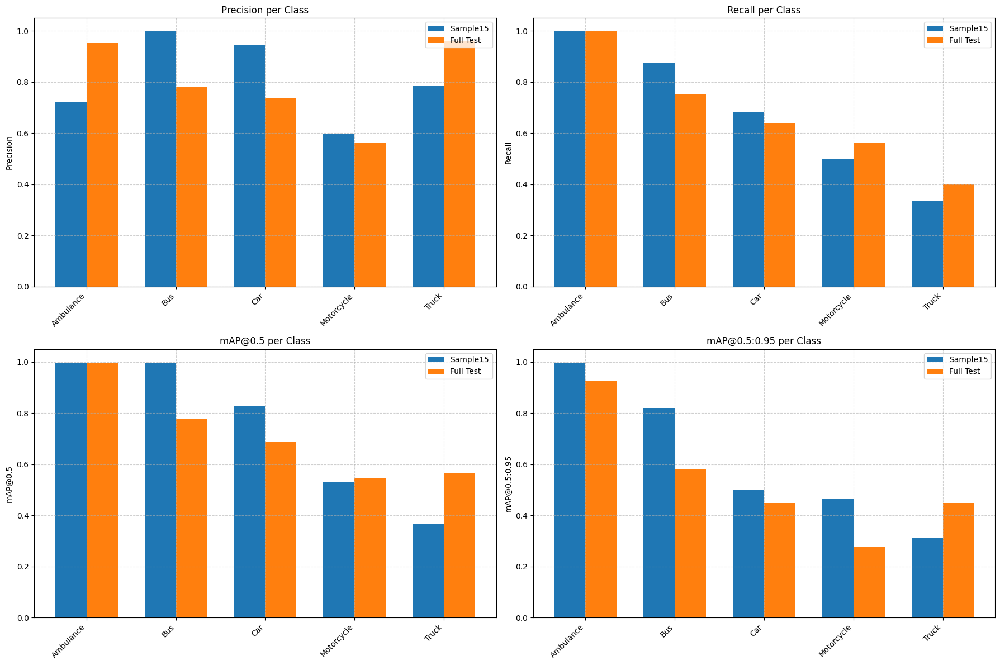

In [63]:

import numpy as np

# Collect per-class metrics for sample and full
metrics = {
    "Precision": [],
    "Recall": [],
    "mAP@0.5": [],
    "mAP@0.5:0.95": []
}

full_metrics = {
    "Precision": [],
    "Recall": [],
    "mAP@0.5": [],
    "mAP@0.5:0.95": []
}

class_labels = []

for i, class_name in sample_val.names.items():
    sp, sr, sm50, sm95 = sample_val.box.class_result(i)
    fp, fr, fm50, fm95 = full_val.box.class_result(i)

    class_labels.append(class_name)

    metrics["Precision"].append(sp)
    metrics["Recall"].append(sr)
    metrics["mAP@0.5"].append(sm50)
    metrics["mAP@0.5:0.95"].append(sm95)

    full_metrics["Precision"].append(fp)
    full_metrics["Recall"].append(fr)
    full_metrics["mAP@0.5"].append(fm50)
    full_metrics["mAP@0.5:0.95"].append(fm95)

# Plot grouped bar charts
x = np.arange(len(class_labels))  # Class indices
width = 0.35  # Bar width

fig, axs = plt.subplots(2, 2, figsize=(18, 12))
axs = axs.flatten()

for idx, metric in enumerate(metrics.keys()):
    ax = axs[idx]
    ax.bar(x - width/2, metrics[metric], width, label='Sample15')
    ax.bar(x + width/2, full_metrics[metric], width, label='Full Test')

    ax.set_title(f'{metric} per Class')
    ax.set_xticks(x)
    ax.set_xticklabels(class_labels, rotation=45, ha='right')
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
